# Week 4：变分自编码器 VAE

## 实验目的

以 PyTorch 官方 MNIST VAE 示例为基础，学习：
- 编码器如何输出均值和对数方差。
- 如何通过重参数化获得潜在向量。
- 解码器如何重建图片。
- 重建损失与 KL 散度分别起什么作用。
- 如何从先验分布采样并生成图片。

完成基础实验后，改变潜在维度与学习率，
观察重建和生成结果的变化。

本实验不使用数字标签训练模型。

普通 AE 的编码器把一张图片转换成一个确定的向量：
$$
x \xrightarrow{\text{Encoder}} z
\xrightarrow{\text{Decoder}} \hat{x}
$$

这里：
- $x$：原始图片。
- $z$：压缩后的潜在表示。
- $\hat{x}$：重建图片。

VAE 的变化发生在编码器输出这里：它先输出一个分布的参数，再从这个分布中采样得到 $z$。

| 环节 | 普通 AE | 本次使用的 VAE |
|---|---|---|
| 编码器输出 | 一个确定的向量 $z$ | 均值向量 $\mu$ 和对数方差向量 $\log\sigma^2$ |
| 解码器输入 | 编码器直接得到的 $z$ | 根据上述分布采样得到的 $z$ |
| 训练目标 | 重建输入 | 重建输入，同时用 KL 项约束潜在分布 |
| 本次观察重点 | 重建图片 | 重建图片，以及随机生成的新图片 |

In [1]:
import sys
import random
import numpy as np
import matplotlib.pyplot as plt

import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

torch.set_num_threads(1)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Python executable:", sys.executable)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("Device:", device)
print("Random seed:", RANDOM_SEED)
print("CPU threads:", torch.get_num_threads())

Python executable: /opt/anaconda3/bin/python
PyTorch version: 2.14.0
Torchvision version: 0.29.0
Device: cpu
Random seed: 42
CPU threads: 1


## 1. 加载并检查 MNIST

使用 MNIST 手写数字图片：
- 训练集：60,000 张。
- 测试集：10,000 张。
- 每张图片为单通道、28 × 28 像素。

使用 ToTensor 将图片转换为张量，并将像素值缩放到 [0, 1]。
本次不额外进行均值和标准差标准化。

VAE 使用图片本身作为重建目标。
数字标签仅用于查看样本，不参与模型训练。

In [2]:
from pathlib import Path

DATA_ROOT = Path("./data").resolve()
BATCH_SIZE = 128

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root=str(DATA_ROOT),
    train=True,
    download=True,
    transform=transform,
)

test_dataset = datasets.MNIST(
    root=str(DATA_ROOT),
    train=False,
    download=True,
    transform=transform,
)

train_generator = torch.Generator().manual_seed(RANDOM_SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=train_generator,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
)

example_images, example_labels = next(iter(test_loader))

print("Data directory:", DATA_ROOT)
print("Training images:", len(train_dataset))
print("Test images:", len(test_dataset))
print("Image batch shape:", example_images.shape)
print("Label batch shape:", example_labels.shape)
print("Image data type:", example_images.dtype)
print("Pixel minimum:", example_images.min().item())
print("Pixel maximum:", example_images.max().item())
print("Flattened batch shape:", example_images.flatten(start_dim=1).shape)

100%|██████████| 9.91M/9.91M [00:01<00:00, 8.19MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 469kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.97MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 25.7MB/s]


Data directory: /Users/cheeseowl/Desktop/科研/data
Training images: 60000
Test images: 10000
Image batch shape: torch.Size([128, 1, 28, 28])
Label batch shape: torch.Size([128])
Image data type: torch.float32
Pixel minimum: 0.0
Pixel maximum: 1.0
Flattened batch shape: torch.Size([128, 784])


理解这几个形状：
| 形状 | 含义 |
|---|---|
| `(128, 1, 28, 28)` | 一批 128 张图片，每张 1 个通道，高宽都是 28 |
| `(128,)` | 每张图片对应一个数字标签 |
| `(128, 784)` | 将每张图片的像素展开，得到长度为 `28 × 28 = 784` 的向量 |

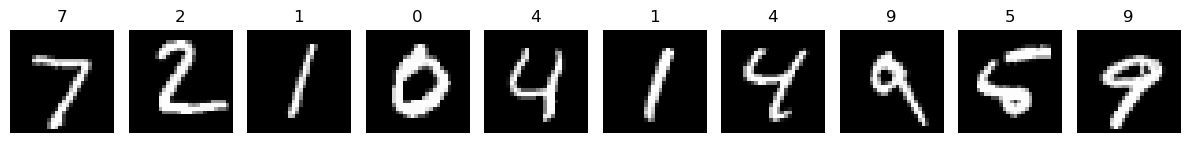

In [ ]:
#显示十张原始图片
fig, axes = plt.subplots(1, 10, figsize=(12, 2))

for i, ax in enumerate(axes):
    ax.imshow(
        example_images[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.set_title(str(example_labels[i].item()))
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2. 构建并检查 VAE 编码器

编码器首先将图片展开为 784 维向量，
经过一个 400 维隐藏层和 ReLU 激活函数，
再通过两个独立的线性层输出：

- mu：20 维均值向量。
- logvar：20 维对数方差向量。

这里的 20 是潜在空间维度，不是数字类别数。
模型不会为每个维度预先指定语义。

本次使用对角高斯分布：
给定一张图片后，用每个潜在维度的均值和方差描述该分布，
不单独学习不同潜在维度之间的协方差。

本单元格仅检查编码器输出，不进行训练。

In [4]:
class VAEEncoder(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()

        self.fc1 = nn.Linear(784, 400)
        self.fc_mu = nn.Linear(400, latent_dim)
        self.fc_logvar = nn.Linear(400, latent_dim)

    def forward(self, x):
        x = x.flatten(start_dim=1)
        hidden = F.relu(self.fc1(x))

        mu = self.fc_mu(hidden)
        logvar = self.fc_logvar(hidden)

        return mu, logvar


torch.manual_seed(RANDOM_SEED)

encoder = VAEEncoder(latent_dim=20).to(device)
encoder.eval()

with torch.no_grad():
    example_mu, example_logvar = encoder(
        example_images.to(device)
    )

print(encoder)
print("\nInput shape:", example_images.shape)
print("Mu shape:", example_mu.shape)
print("Logvar shape:", example_logvar.shape)

print("\nFirst image, first 5 mu values:")
print(example_mu[0, :5].cpu().numpy())

print("\nFirst image, first 5 logvar values:")
print(example_logvar[0, :5].cpu().numpy())

VAEEncoder(
  (fc1): Linear(in_features=784, out_features=400, bias=True)
  (fc_mu): Linear(in_features=400, out_features=20, bias=True)
  (fc_logvar): Linear(in_features=400, out_features=20, bias=True)
)

Input shape: torch.Size([128, 1, 28, 28])
Mu shape: torch.Size([128, 20])
Logvar shape: torch.Size([128, 20])

First image, first 5 mu values:
[-0.10081694 -0.0769191   0.03110166  0.07196144 -0.11224726]

First image, first 5 logvar values:
[ 0.03389277 -0.04257159 -0.02699556  0.04062636  0.011267  ]


## 3. 重参数化：从分布参数得到潜在向量

编码器输出均值向量 $\mu$ 和对数方差向量 $\log\sigma^2$。

先计算标准差：

$$
\sigma=\exp\left(\frac{\text{logvar}}{2}\right)
$$

再生成标准正态噪声：

$$
\epsilon\sim\mathcal{N}(0,I)
$$

最后计算：

$$
z=\mu+\sigma\odot\epsilon
$$

其中 $\odot$ 表示逐元素相乘。

给定图片后，这样得到的 $z$ 来自编码器描述的对角高斯分布。
同一张图片的分布参数不变时，多次采样仍可以得到不同的 $z$。

重参数化将随机性放在噪声中，
使梯度能够通过均值和标准差传回编码器。

本单元格只检查采样结果，不进行训练。

In [5]:
def reparameterize(mu, logvar):
    std = torch.exp(0.5 * logvar)
    epsilon = torch.randn_like(std)

    return mu + std * epsilon


with torch.no_grad():
    example_std = torch.exp(0.5 * example_logvar)

    example_z_1 = reparameterize(example_mu, example_logvar)
    example_z_2 = reparameterize(example_mu, example_logvar)

print("Std shape:", example_std.shape)
print("First sampled z shape:", example_z_1.shape)
print("Second sampled z shape:", example_z_2.shape)

print("\nFirst image, first 5 std values:")
print(example_std[0, :5].cpu().numpy())

print("\nFirst image, first 5 z values, sample 1:")
print(example_z_1[0, :5].cpu().numpy())

print("\nFirst image, first 5 z values, sample 2:")
print(example_z_2[0, :5].cpu().numpy())

print(
    "\nAre the two samples approximately equal?",
    torch.allclose(example_z_1, example_z_2),
)

Std shape: torch.Size([128, 20])
First sampled z shape: torch.Size([128, 20])
Second sampled z shape: torch.Size([128, 20])

First image, first 5 std values:
[1.0170908 0.9789392 0.9865929 1.0205209 1.0056494]

First image, first 5 z values, sample 1:
[ 1.1970999   0.3874774   1.3889251  -0.30448726 -1.5817199 ]

First image, first 5 z values, sample 2:
[-1.6350075  -1.3204615   0.41126764  0.8019237  -1.8690048 ]

Are the two samples approximately equal? False


## 4. 构建并检查 VAE 解码器

解码器接收 20 维潜在向量 $z$：
- 通过线性层转换为 400 维隐藏表示。
- 使用 ReLU 激活函数。
- 通过输出层转换为 784 维。
- 使用 Sigmoid 将输出限制在 [0, 1]。

每个输出值对应一个重建像素，不要求所有像素值之和为 1。

输出可以重新排列为单通道、28 × 28 的图片。
恢复形状不会改变像素值。

本单元格只检查解码器输出，不进行训练。

In [6]:
class VAEDecoder(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()

        self.fc1 = nn.Linear(latent_dim, 400)
        self.fc2 = nn.Linear(400, 784)

    def forward(self, z):
        hidden = F.relu(self.fc1(z))
        reconstruction = torch.sigmoid(self.fc2(hidden))

        return reconstruction


decoder = VAEDecoder(latent_dim=20).to(device)
decoder.eval()

with torch.no_grad():
    example_reconstruction = decoder(example_z_1)

    example_reconstruction_images = (
        example_reconstruction.reshape(-1, 1, 28, 28)
    )

print(decoder)
print("\nLatent input shape:", example_z_1.shape)
print("Decoder output shape:", example_reconstruction.shape)
print("Reconstructed image shape:", example_reconstruction_images.shape)
print("Output minimum:", example_reconstruction.min().item())
print("Output maximum:", example_reconstruction.max().item())

VAEDecoder(
  (fc1): Linear(in_features=20, out_features=400, bias=True)
  (fc2): Linear(in_features=400, out_features=784, bias=True)
)

Latent input shape: torch.Size([128, 20])
Decoder output shape: torch.Size([128, 784])
Reconstructed image shape: torch.Size([128, 1, 28, 28])
Output minimum: 0.22265109419822693
Output maximum: 0.7589940428733826


## 5. 组成完整 VAE

将已经定义的编码器、重参数化函数和解码器连接起来：

1. 编码器根据输入图片计算 mu 和 logvar。
2. 重参数化函数根据这两个参数采样得到 z。
3. 解码器根据 z 输出重建图片。

前向传播返回 reconstruction、mu 和 logvar：
- reconstruction 用于计算重建损失。
- mu 和 logvar 用于计算 KL 散度。

完整过程是：
$$
x\rightarrow(\mu,\text{logvar})\rightarrow z\rightarrow\hat{x}
$$

In [7]:
class VAE(nn.Module):
    def __init__(self, latent_dim=20):
        super().__init__()

        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = reparameterize(mu, logvar)
        reconstruction = self.decoder(z)

        return reconstruction, mu, logvar


torch.manual_seed(RANDOM_SEED)

model = VAE(latent_dim=20).to(device)
model.eval()

with torch.no_grad():
    reconstruction, mu, logvar = model(
        example_images.to(device)
    )

print("Reconstruction shape:", reconstruction.shape)
print("Mu shape:", mu.shape)
print("Logvar shape:", logvar.shape)

Reconstruction shape: torch.Size([128, 784])
Mu shape: torch.Size([128, 20])
Logvar shape: torch.Size([128, 20])


## 6. 定义 VAE 损失函数

总损失为：

$$
L=L_{\mathrm{reconstruction}}+L_{\mathrm{KL}}
$$

### 重建损失

使用二元交叉熵（BCE）比较重建像素与原始像素。
本实验沿用官方示例，将 [0, 1] 内的灰度值作为 BCE 的目标。

先对一批图片的所有像素求和，再除以批次中的图片数量，
得到每张图片的平均重建损失。

### KL 散度

编码器描述的分布为：

$$
q_\phi(z\mid x)
=
\mathcal{N}\left(\mu,\operatorname{diag}(\sigma^2)\right)
$$

指定先验为：

$$
p(z)=\mathcal{N}(0,I)
$$

对于一张图片，KL 项可以计算为：

$$
L_{\mathrm{KL}}
=
\frac{1}{2}
\sum_{j=1}^{d}
\left(
\mu_j^2+\exp(\mathrm{logvar}_j)-1-\mathrm{logvar}_j
\right)
$$

其中 d 是潜在维度，本次为 20。

代码对整批图片和全部潜在维度求和，再除以图片数量，
得到每张图片的平均 KL 散度。

总损失、重建损失和 KL 散度均使用每张图片的平均值。
数字类别标签不参与损失计算。

In [8]:
def vae_loss(reconstruction, images, mu, logvar):
    batch_size = images.size(0)
    target = images.flatten(start_dim=1)

    reconstruction_loss = F.binary_cross_entropy(
        reconstruction,
        target,
        reduction="sum",
    ) / batch_size

    kl_loss = 0.5 * torch.sum(
        mu.pow(2) + logvar.exp() - 1 - logvar
    ) / batch_size

    total_loss = reconstruction_loss + kl_loss

    return total_loss, reconstruction_loss, kl_loss


model.eval()

with torch.no_grad():
    images = example_images.to(device)
    reconstruction, mu, logvar = model(images)

    total_loss, reconstruction_loss, kl_loss = vae_loss(
        reconstruction,
        images,
        mu,
        logvar,
    )

print(f"Total loss per image: {total_loss.item():.4f}")
print(f"Reconstruction loss per image: {reconstruction_loss.item():.4f}")
print(f"KL loss per image: {kl_loss.item():.4f}")

Total loss per image: 547.5473
Reconstruction loss per image: 547.4414
KL loss per image: 0.1059


## 7. 基础实验：训练 VAE

实验设置：
- 数据：完整 MNIST 训练集与测试集。
- 隐藏层维度：400。
- 潜在维度：20。
- Batch size：128。
- 优化器：Adam。
- 学习率：0.001。
- 训练轮数：10。
- 随机种子：42。
- 损失：重建 BCE + KL 散度，KL 权重为 1。

每轮记录训练集和测试集上的：
- 总损失。
- 重建损失。
- KL 散度。

所有损失均按图片数量取平均。
测试阶段不计算梯度，不更新参数。
数字标签不参与训练。

VAE 的前向传播包含随机采样，
因此测试损失可能存在一定波动。


In [9]:
def run_epoch(model, loader, optimizer=None):
    is_training = optimizer is not None
    model.train(is_training)

    total_sum = 0.0
    reconstruction_sum = 0.0
    kl_sum = 0.0
    image_count = 0

    with torch.set_grad_enabled(is_training):
        for images, _ in loader:
            images = images.to(device)
            batch_size = images.size(0)

            if is_training:
                optimizer.zero_grad()

            reconstruction, mu, logvar = model(images)

            total_loss, reconstruction_loss, kl_loss = vae_loss(
                reconstruction,
                images,
                mu,
                logvar,
            )

            if is_training:
                total_loss.backward()
                optimizer.step()

            total_sum += total_loss.item() * batch_size
            reconstruction_sum += reconstruction_loss.item() * batch_size
            kl_sum += kl_loss.item() * batch_size
            image_count += batch_size

    return {
        "total": total_sum / image_count,
        "reconstruction": reconstruction_sum / image_count,
        "kl": kl_sum / image_count,
    }

| 代码 | 作用 |
|---|---|
| `for images, _ in loader` | 读取图片，忽略数字标签 |
| `torch.set_grad_enabled(is_training)` | 训练时记录梯度，评估时关闭梯度记录 |
| `backward()` 和 `step()` | 计算梯度，再更新模型参数，只在训练时执行 |

In [10]:
import time

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
train_generator.manual_seed(RANDOM_SEED)

LATENT_DIM = 20
LEARNING_RATE = 0.001
EPOCHS = 10

model = VAE(latent_dim=LATENT_DIM).to(device)
optimizer = optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

history = []
start_time = time.perf_counter()

for epoch in range(1, EPOCHS + 1):
    train_metrics = run_epoch(model, train_loader, optimizer)
    test_metrics = run_epoch(model, test_loader)

    history.append({
        "epoch": epoch,
        "train_total": train_metrics["total"],
        "train_reconstruction": train_metrics["reconstruction"],
        "train_kl": train_metrics["kl"],
        "test_total": test_metrics["total"],
        "test_reconstruction": test_metrics["reconstruction"],
        "test_kl": test_metrics["kl"],
    })

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train total: {train_metrics['total']:.2f} | "
        f"Recon: {train_metrics['reconstruction']:.2f} | "
        f"KL: {train_metrics['kl']:.2f} | "
        f"Test total: {test_metrics['total']:.2f}",
        flush=True,
    )

elapsed_time = time.perf_counter() - start_time
print(f"\nTraining completed in {elapsed_time:.1f} seconds.")

Epoch 01/10 | Train total: 162.89 | Recon: 146.91 | KL: 15.99 | Test total: 126.58
Epoch 02/10 | Train total: 121.34 | Recon: 98.97 | KL: 22.38 | Test total: 115.76
Epoch 03/10 | Train total: 114.68 | Recon: 90.88 | KL: 23.81 | Test total: 111.84
Epoch 04/10 | Train total: 111.85 | Recon: 87.47 | KL: 24.37 | Test total: 109.90
Epoch 05/10 | Train total: 110.04 | Recon: 85.38 | KL: 24.66 | Test total: 108.57
Epoch 06/10 | Train total: 108.92 | Recon: 84.04 | KL: 24.88 | Test total: 107.59
Epoch 07/10 | Train total: 108.03 | Recon: 83.04 | KL: 24.99 | Test total: 107.21
Epoch 08/10 | Train total: 107.41 | Recon: 82.32 | KL: 25.09 | Test total: 106.41
Epoch 09/10 | Train total: 106.87 | Recon: 81.72 | KL: 25.15 | Test total: 106.22
Epoch 10/10 | Train total: 106.44 | Recon: 81.22 | KL: 25.22 | Test total: 105.70

Training completed in 25.5 seconds.


| 指标 | 第 1 轮 | 第 10 轮 | 观察 |
|---|---:|---:|---|
| 训练总损失 | 162.89 | 106.44 | 持续下降 |
| 训练重建损失 | 146.91 | 81.22 | 图片重建逐渐改善 |
| 训练 KL | 15.99 | 25.22 | 上升后逐渐趋稳 |
| 测试总损失 | 126.58 | 105.70 | 持续下降 |

## 8. 基础实验的训练观察

训练 10 轮后：
- 训练总损失从约 162.89 降至 106.44。
- 训练重建损失从约 146.91 降至 81.22。
- 训练 KL 从约 15.99 升至 25.22，后期变化逐渐减小。
- 测试总损失从约 126.58 降至 105.70。

重建损失下降的同时，KL 上升并逐渐趋稳，
表明模型在重建输入与约束潜在分布之间进行权衡。

当前测试总损失没有出现持续上升，
但不能仅凭这些数值断定模型已经充分收敛或不存在过拟合。

下一步查看损失曲线与重建图片。

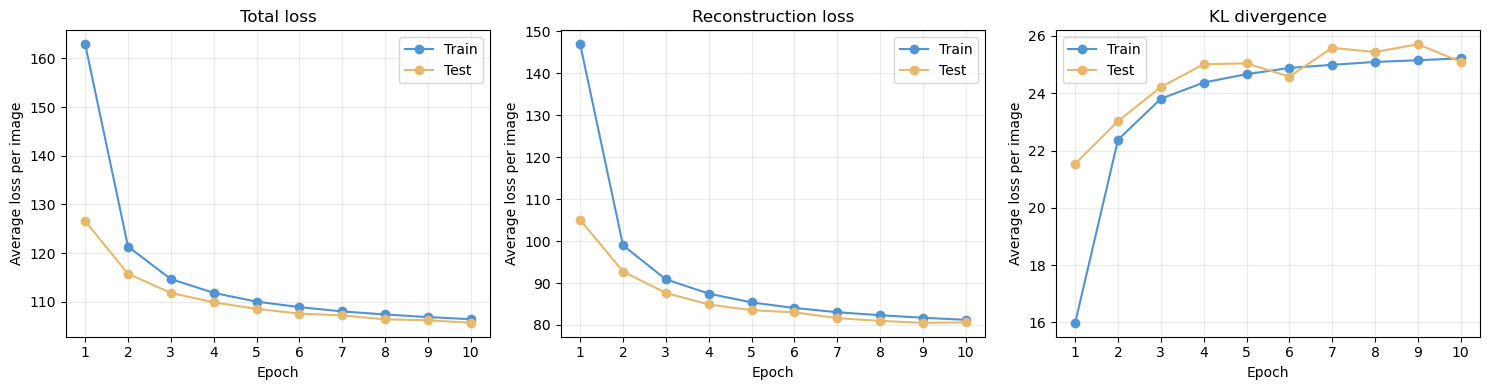

In [11]:
epochs = [row["epoch"] for row in history]

plot_settings = [
    ("total", "Total loss"),
    ("reconstruction", "Reconstruction loss"),
    ("kl", "KL divergence"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (metric, title) in zip(axes, plot_settings):
    train_values = [row[f"train_{metric}"] for row in history]
    test_values = [row[f"test_{metric}"] for row in history]

    ax.plot(
        epochs,
        train_values,
        marker="o",
        color="#5094D5",
        label="Train",
    )

    ax.plot(
        epochs,
        test_values,
        marker="o",
        color="#E8B86C",
        label="Test",
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Average loss per image")
    ax.set_xticks(epochs)
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

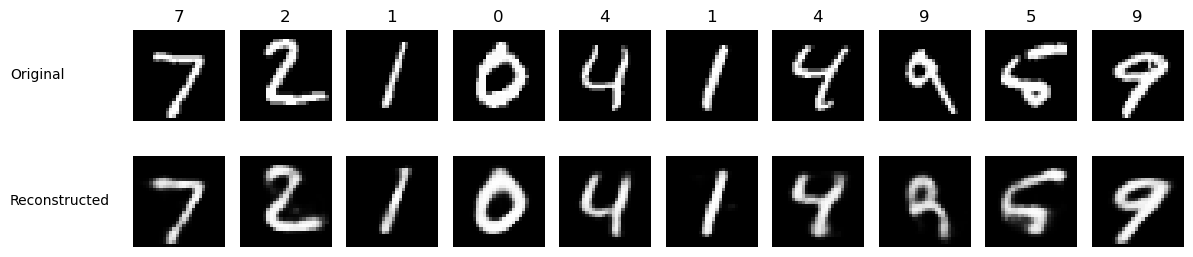

In [12]:
model.eval()

with torch.no_grad():
    fixed_images = example_images[:10].to(device)

    reconstructed, _, _ = model(fixed_images)
    reconstructed = reconstructed.reshape(-1, 1, 28, 28).cpu()

originals = fixed_images.cpu()

fig, axes = plt.subplots(2, 10, figsize=(12, 3))

for i in range(10):
    axes[0, i].imshow(
        originals[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[1, i].imshow(
        reconstructed[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    axes[0, i].set_title(str(example_labels[i].item()))
    axes[0, i].axis("off")
    axes[1, i].axis("off")

fig.text(0.01, 0.70, "Original", va="center")
fig.text(0.01, 0.28, "Reconstructed", va="center")

plt.tight_layout(rect=[0.10, 0, 1, 1])
plt.show()

### 基础实验的可视化观察

训练与测试总损失、重建损失均随训练下降，后期下降速度减慢。
KL 散度前期上升，后期在约 25 附近波动。

在展示的十张测试图片中：
- 重建图基本保留了原图的数字形状。
- 部分笔画边缘变得平滑、模糊。
- 细节与笔画粗细存在变化。

这些结果说明模型能够重建所展示的测试样本，
但不能仅凭十张示例判断整个测试集的重建质量。


## 9. 从先验分布随机生成图片

直接从标准正态先验中采样 64 个潜在向量：

$$
z\sim\mathcal{N}(0,I)
$$

每个向量有 20 个维度。
将这些向量输入训练好的解码器，生成 64 张图片。

本过程不输入原始图片，不经过编码器，也不指定数字类别。

使用独立的随机数生成器固定采样结果，
方便之后复现和比较。

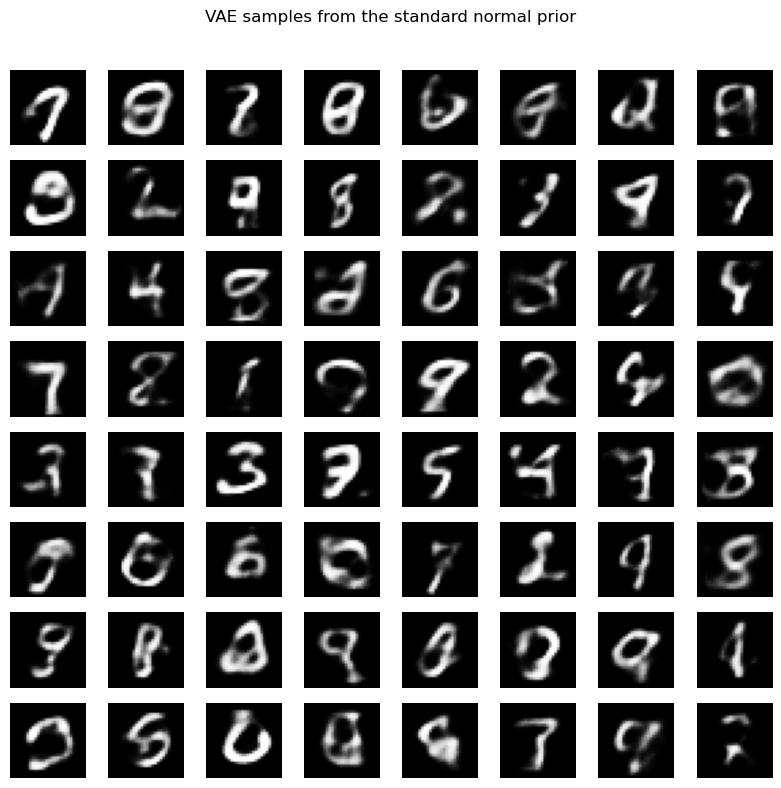

In [13]:
sample_generator = torch.Generator().manual_seed(RANDOM_SEED)

fixed_prior_z = torch.randn(
    64,
    20,
    generator=sample_generator,
).to(device)

model.eval()

with torch.no_grad():
    generated_images = model.decoder(fixed_prior_z)
    generated_images = generated_images.reshape(-1, 1, 28, 28).cpu()

fig, axes = plt.subplots(8, 8, figsize=(8, 8))

for i, ax in enumerate(axes.flat):
    ax.imshow(
        generated_images[i, 0].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )
    ax.axis("off")

fig.suptitle("VAE samples from the standard normal prior")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

### 随机生成结果观察

从标准正态先验采样潜在向量，直接输入解码器后，
可以生成具有手写数字特征的图片。

在展示的 64 张图片中：
- 多张图片具有可辨认的数字形状。
- 笔画粗细和书写方式存在变化。
- 部分图片模糊、残缺，或难以确定对应哪个数字。

这些结果说明模型能够在不输入原图的情况下生成数字样式，
但仅凭这组图片无法评价整体生成质量或类别均衡性。

## 10. 参数实验：潜在维度从 20 改为 2

保持数据、隐藏层维度、学习率、批次大小、
训练轮数和随机种子设置一致，仅修改潜在维度。

比较目标：
- 总损失、重建损失和 KL 散度如何变化？
- 重建图片是否丢失更多细节？
- 随机生成图片是否仍容易辨认？

每个实验都从新初始化的模型开始训练。
保留基础实验模型和训练记录，供后续比较。

In [14]:
baseline_model = model
baseline_history = [row.copy() for row in history]


def train_vae_experiment(latent_dim, learning_rate, epochs=10):
    random.seed(RANDOM_SEED)
    np.random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)
    train_generator.manual_seed(RANDOM_SEED)

    experiment_model = VAE(latent_dim=latent_dim).to(device)

    experiment_optimizer = optim.Adam(
        experiment_model.parameters(),
        lr=learning_rate,
    )

    experiment_history = []
    start_time = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_metrics = run_epoch(
            experiment_model,
            train_loader,
            experiment_optimizer,
        )

        test_metrics = run_epoch(
            experiment_model,
            test_loader,
        )

        experiment_history.append({
            "epoch": epoch,
            "train_total": train_metrics["total"],
            "train_reconstruction": train_metrics["reconstruction"],
            "train_kl": train_metrics["kl"],
            "test_total": test_metrics["total"],
            "test_reconstruction": test_metrics["reconstruction"],
            "test_kl": test_metrics["kl"],
        })

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"Train total: {train_metrics['total']:.2f} | "
            f"Recon: {train_metrics['reconstruction']:.2f} | "
            f"KL: {train_metrics['kl']:.2f} | "
            f"Test total: {test_metrics['total']:.2f}",
            flush=True,
        )

    elapsed_time = time.perf_counter() - start_time
    print(f"\nTraining completed in {elapsed_time:.1f} seconds.")

    return experiment_model, experiment_history

In [15]:
model_dim2, history_dim2 = train_vae_experiment(
    latent_dim=2,
    learning_rate=0.001,
    epochs=10,
)

Epoch 01/10 | Train total: 189.88 | Recon: 183.91 | KL: 5.97 | Test total: 170.12
Epoch 02/10 | Train total: 167.53 | Recon: 162.15 | KL: 5.39 | Test total: 164.34
Epoch 03/10 | Train total: 163.56 | Recon: 158.14 | KL: 5.42 | Test total: 161.89
Epoch 04/10 | Train total: 161.41 | Recon: 155.96 | KL: 5.45 | Test total: 160.10
Epoch 05/10 | Train total: 159.93 | Recon: 154.44 | KL: 5.49 | Test total: 159.14
Epoch 06/10 | Train total: 158.74 | Recon: 153.19 | KL: 5.56 | Test total: 157.84
Epoch 07/10 | Train total: 157.79 | Recon: 152.19 | KL: 5.60 | Test total: 157.53
Epoch 08/10 | Train total: 156.87 | Recon: 151.22 | KL: 5.66 | Test total: 156.24
Epoch 09/10 | Train total: 156.12 | Recon: 150.41 | KL: 5.71 | Test total: 155.95
Epoch 10/10 | Train total: 155.33 | Recon: 149.57 | KL: 5.76 | Test total: 155.37

Training completed in 24.1 seconds.


### 潜在维度实验的数值观察

在相同学习率和 10 轮训练设置下：

| 第 10 轮指标 | 20 维 | 2 维 |
|---|---:|---:|
| 训练总损失 | 106.44 | 155.33 |
| 训练重建损失 | 81.22 | 149.57 |
| 训练 KL | 25.22 | 5.76 |
| 测试总损失 | 105.70 | 155.37 |

本次实验中，2 维模型的训练重建损失和测试总损失更高。

2 维模型的 KL 更小，但 KL 对潜在维度求和，
不能单独根据较小的 KL 判断模型更好。

下一步使用相同测试图片比较重建效果。

### 重建图片对比

使用相同的十张测试图片，分别输入 20 维和 2 维模型。

为了消除本次显示中的采样波动，
两个模型都使用 z = mu，再通过解码器重建。

这属于均值潜在向量重建，与前面随机采样的重建方式不同。
训练方法没有改变。

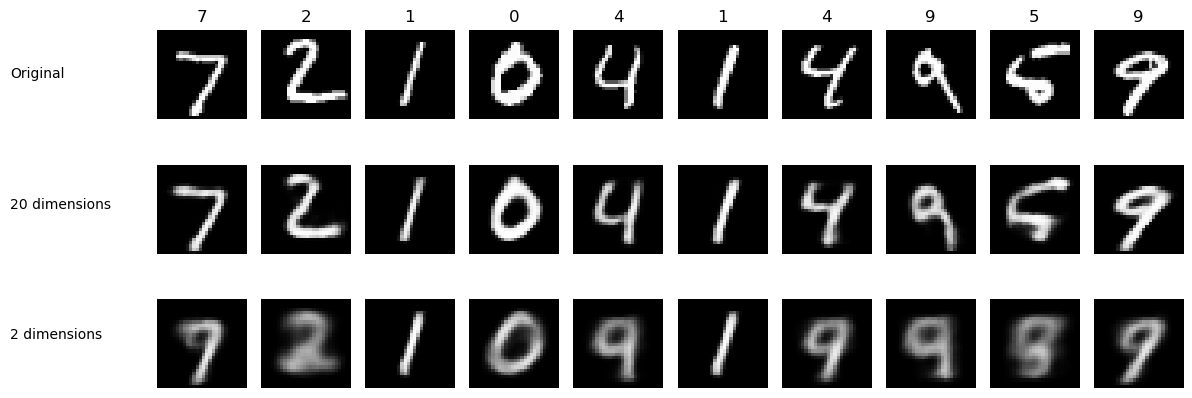

In [16]:
baseline_model.eval()
model_dim2.eval()

with torch.no_grad():
    comparison_images = example_images[:10].to(device)

    mu_20, _ = baseline_model.encoder(comparison_images)
    mu_2, _ = model_dim2.encoder(comparison_images)

    reconstruction_20 = baseline_model.decoder(mu_20)
    reconstruction_2 = model_dim2.decoder(mu_2)

    image_rows = [
        comparison_images.cpu(),
        reconstruction_20.reshape(-1, 1, 28, 28).cpu(),
        reconstruction_2.reshape(-1, 1, 28, 28).cpu(),
    ]

fig, axes = plt.subplots(3, 10, figsize=(12, 4.5))

for row_index, image_batch in enumerate(image_rows):
    for column_index in range(10):
        ax = axes[row_index, column_index]

        ax.imshow(
            image_batch[column_index, 0].numpy(),
            cmap="gray",
            vmin=0,
            vmax=1,
        )

        ax.axis("off")

        if row_index == 0:
            ax.set_title(str(example_labels[column_index].item()))

fig.text(0.01, 0.79, "Original", va="center")
fig.text(0.01, 0.50, "20 dimensions", va="center")
fig.text(0.01, 0.21, "2 dimensions", va="center")

plt.tight_layout(rect=[0.12, 0, 1, 1])
plt.show()

### 潜在维度实验的重建图片观察

两个模型使用相同的十张测试图片，
并统一通过 Decoder(mu) 进行重建。

观察结果：
- 20 维模型较好地保留了数字的主要形状与笔画结构。
- 2 维模型的重建更加模糊，部分数字形状发生变化。
- 两张数字 1 的简单笔画仍较清楚。
- 两张数字 4 的重建更接近 9，数字 2 和 5 的细节也明显丢失。

结合损失结果，在当前网络与 10 轮训练设置下，
2 维模型的重建质量低于 20 维模型。

## 11. 参数实验：降低学习率

将学习率从 0.001 改为 0.0003，
潜在维度保持为 20，其余实验设置保持一致。

从新初始化的模型开始训练，不接着基础模型继续训练。

比较目标：
- 损失下降速度是否改变？
- 相同 10 轮训练后，损失是否更低？
- 重建图片与随机生成图片有什么变化？

本实验比较固定训练轮数下的结果，
不能据此判断两个学习率在充分训练后各自能达到的最好效果。

In [17]:
model_lr_small, history_lr_small = train_vae_experiment(
    latent_dim=20,
    learning_rate=0.0003,
    epochs=10,
)

Epoch 01/10 | Train total: 204.31 | Recon: 189.74 | KL: 14.57 | Test total: 152.65
Epoch 02/10 | Train total: 141.07 | Recon: 120.86 | KL: 20.21 | Test total: 131.31
Epoch 03/10 | Train total: 128.01 | Recon: 105.72 | KL: 22.30 | Test total: 122.97
Epoch 04/10 | Train total: 121.83 | Recon: 98.47 | KL: 23.36 | Test total: 118.44
Epoch 05/10 | Train total: 118.18 | Recon: 94.23 | KL: 23.96 | Test total: 115.73
Epoch 06/10 | Train total: 115.72 | Recon: 91.34 | KL: 24.39 | Test total: 113.56
Epoch 07/10 | Train total: 113.91 | Recon: 89.26 | KL: 24.65 | Test total: 112.18
Epoch 08/10 | Train total: 112.57 | Recon: 87.70 | KL: 24.87 | Test total: 111.13
Epoch 09/10 | Train total: 111.45 | Recon: 86.46 | KL: 25.00 | Test total: 110.21
Epoch 10/10 | Train total: 110.58 | Recon: 85.46 | KL: 25.12 | Test total: 109.23

Training completed in 23.6 seconds.


## 12. 三组实验结果比较

所有实验均训练 10 轮，batch size 为 128，随机种子为 42。

| 实验 | 潜在维度 | 学习率 | 训练总损失 | 训练重建损失 | 训练 KL | 测试总损失 |
|---|---:|---:|---:|---:|---:|---:|
| 基础实验 | 20 | 0.001 | 106.44 | 81.22 | 25.22 | 105.70 |
| 减少潜在维度 | 2 | 0.001 | 155.33 | 149.57 | 5.76 | 155.37 |
| 降低学习率 | 20 | 0.0003 | 110.58 | 85.46 | 25.12 | 109.23 |

所有损失均为每张图片的平均值。

本次实验中：
- 20 维、学习率 0.001 的模型具有最低的测试总损失。
- 将潜在维度减少到 2 后，重建损失明显增加。
- 将学习率降低到 0.0003 后，在相同训练轮数下损失下降进度较慢。
- 两个 20 维模型的训练 KL 接近，差异主要来自重建项。

以上结果来自单个随机种子和固定的训练预算，
不能据此判断各设置充分训练后能达到的最好效果。

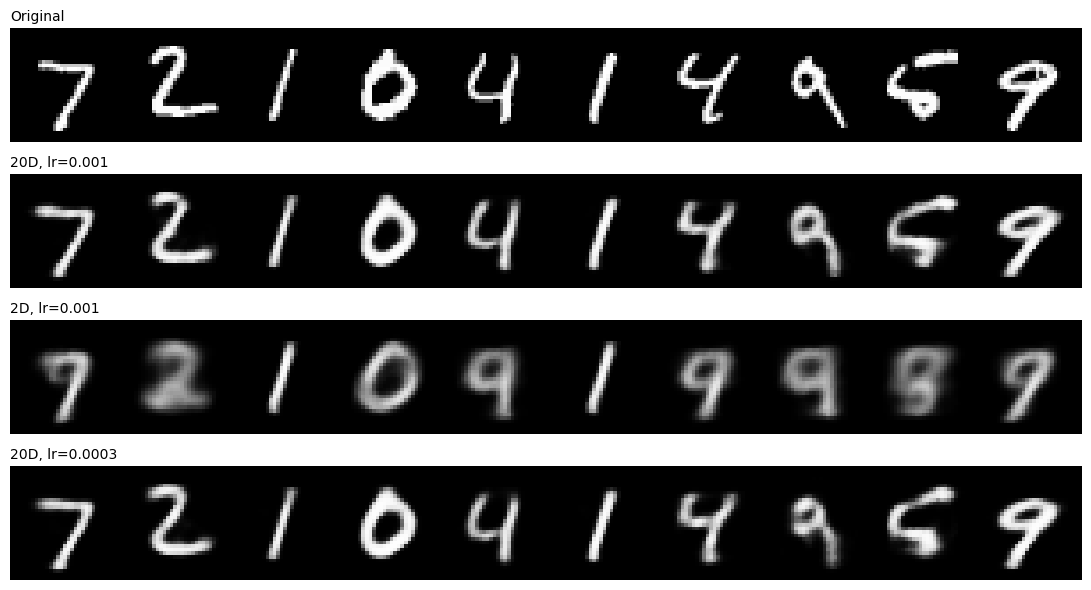

In [18]:
from torchvision.utils import make_grid

comparison_models = [
    ("20D, lr=0.001", baseline_model, 20),
    ("2D, lr=0.001", model_dim2, 2),
    ("20D, lr=0.0003", model_lr_small, 20),
]

comparison_images = example_images[:10].to(device)
reconstruction_rows = [("Original", comparison_images.cpu())]

for name, current_model, latent_dim in comparison_models:
    current_model.eval()

    with torch.no_grad():
        mu, _ = current_model.encoder(comparison_images)
        reconstructed = current_model.decoder(mu)
        reconstructed = reconstructed.reshape(-1, 1, 28, 28).cpu()

    reconstruction_rows.append((name, reconstructed))

fig, axes = plt.subplots(4, 1, figsize=(12, 6))

for ax, (name, images) in zip(axes, reconstruction_rows):
    grid = make_grid(images, nrow=10, padding=2, normalize=False)

    ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
    ax.set_title(name, loc="left", fontsize=10)
    ax.axis("off")

plt.tight_layout()
plt.show()

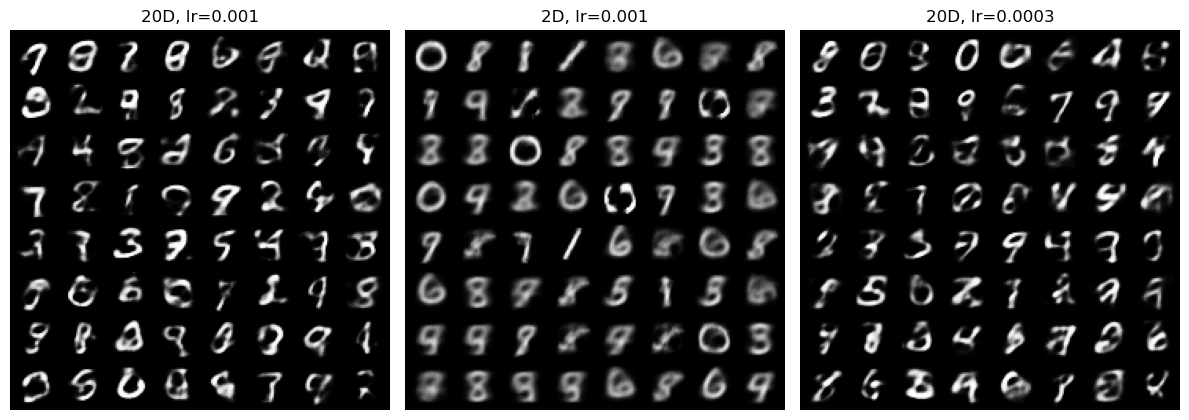

In [19]:
comparison_generator = torch.Generator().manual_seed(RANDOM_SEED)

comparison_noise = torch.randn(
    64,
    20,
    generator=comparison_generator,
)

fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for ax, (name, current_model, latent_dim) in zip(
    axes,
    comparison_models,
):
    current_model.eval()
    z = comparison_noise[:, :latent_dim].to(device)

    with torch.no_grad():
        samples = current_model.decoder(z)
        samples = samples.reshape(-1, 1, 28, 28).cpu()

    grid = make_grid(samples, nrow=8, padding=2, normalize=False)

    ax.imshow(grid.permute(1, 2, 0).numpy(), vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis("off")

plt.tight_layout()
plt.show()

## 13. 参数实验的图片观察与结论

### 重建图片

所有模型使用相同的十张测试图片，
并统一通过 Decoder(mu) 重建。

- 两个 20 维模型均较好地保留了主要数字形状，
  在这组示例中的视觉差异较小。
- 2 维模型的重建更加模糊，部分数字结构发生变化。
- 2 维模型将两张数字 4 重建得更接近 9，
  数字 2 和 5 的细节也明显丢失。
- 数字 1 的简单笔画在三个模型中均得到较好保留。

### 随机生成图片

每个模型均从对应维度的标准正态先验采样，
不输入原始图片或数字标签。

- 三个模型都能生成具有手写数字特征的图片。
- 2 维模型仍能生成可辨认的数字，
  但部分样本模糊或具有混合形状。
- 两个 20 维模型也存在不清晰、残缺的生成样本。
- 仅凭这组生成图，无法确定两个 20 维模型整体生成质量的优劣。

两个 20 维模型使用相同的潜在向量。
不同模型的潜在坐标并未对齐，
同一位置不要求生成相同数字。

### 实验结论

在本次网络结构、随机种子和 10 轮训练设置下：

1. 将潜在维度从 20 减少到 2，重建损失明显增加，
   展示的重建图也丢失了更多结构与细节。

2. 将学习率从 0.001 降低到 0.0003，
   相同训练轮数下的损失下降进度较慢。
   两个 20 维模型展示的重建图片仍较接近。

3. 基础实验的测试总损失最低，
   但这不直接证明它的生成图片质量最好。

以上属于单个随机种子下的实验观察，
不代表所有网络或训练预算都会得到相同结论。

## 14. VAE 核心概念回顾

| 概念 | 在本实验中的含义 |
|---|---|
| 潜在变量 z | 解码器使用的低维隐藏表示 |
| 先验分布 p(z) | 指定的标准正态分布，用于随机生成时采样 |
| 近似后验 q(z\|x) | 编码器根据具体图片估计的潜在分布，用来近似真实后验 |
| 均值 mu | 决定该潜在分布的位置 |
| 方差 sigma² | 决定该分布各维度的分散程度 |
| 采样 | 根据分布产生一个具体的潜在向量 |
| 重参数化 | 使用 z = mu + sigma × epsilon，让梯度能够通过分布参数传回编码器 |
| 重建损失 | 衡量重建像素与输入像素的差异 |
| KL 散度 | 衡量编码器给出的分布偏离指定先验的程度 |

训练时使用：

$$
z=\mu+\exp(0.5\,\mathrm{logvar})\odot\epsilon,
\qquad \epsilon\sim\mathcal{N}(0,I)
$$

损失为：

$$
L=L_{\mathrm{reconstruction}}+L_{\mathrm{KL}}
$$

随机生成时直接从先验采样 z，再输入解码器，不经过编码器。

## 15. AE、VAE、LDA 与 K-means 的区别

| 方法 | 主要学习什么 | 典型输出 |
|---|---|---|
| AE | 用于重建输入的压缩表示 | 确定的潜在向量与重建结果 |
| VAE | 近似后验分布与生成解码器 | 均值、对数方差、重建结果与生成样本 |
| LDA | 文档的主题混合与各主题的词语分布 | 文档—主题分布、主题—词分布 |
| K-means | 使簇内平方距离和较小的簇中心与分组 | 每个样本的一个簇编号 |

AE 与 VAE 可以学习表示，再将表示交给 K-means 聚类。
LDA 本身输出主题混合比例，不要求每篇文档只涉及一个主题。
这些方法在本作业的无监督训练过程中都不使用类别标签。


In [20]:
save_directory = Path("./results/week4_vae")
save_directory.mkdir(parents=True, exist_ok=True)

experiments_to_save = [
    ("baseline", baseline_model, baseline_history, 20, 0.001),
    ("latent2", model_dim2, history_dim2, 2, 0.001),
    ("small_lr", model_lr_small, history_lr_small, 20, 0.0003),
]

for name, current_model, records, latent_dim, learning_rate in experiments_to_save:
    checkpoint = {
        "state_dict": {
            key: value.detach().cpu().clone()
            for key, value in current_model.state_dict().items()
        },
        "latent_dim": latent_dim,
        "hidden_dim": 400,
        "learning_rate": learning_rate,
        "epochs": len(records),
        "batch_size": BATCH_SIZE,
        "random_seed": RANDOM_SEED,
        "history": records,
    }

    save_path = save_directory / f"{name}.pt"
    torch.save(checkpoint, save_path)
    print("Saved:", save_path.resolve())

Saved: /Users/cheeseowl/Desktop/科研/results/week4_vae/baseline.pt
Saved: /Users/cheeseowl/Desktop/科研/results/week4_vae/latent2.pt
Saved: /Users/cheeseowl/Desktop/科研/results/week4_vae/small_lr.pt
